In [ ]:
import sys
sys.executable, sys.version


('e:\\APP\\Anaconda\\python.exe',
 '3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:17:27) [MSC v.1929 64 bit (AMD64)]')

In [4]:
#基础模型
# 开关: two_sided双尾+门控+幂变换
# 固定使用optuna搜索FPR阈值

import os
import numpy as np
import pandas as pd
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from dataclasses import dataclass, field
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix,
    roc_auc_score,
)

# =========================
# 路径配置
# =========================

software = "contrast_dataset_bind9.18.6"
x = "camp"

benign_train_path = f"./{software}/good/normalized_dataset.csv"
benign_test_path = f"./{software}/good/normalized_dataset_test.csv"
malicious_train_path = f"./{software}/{x}/train_normalized.csv"
malicious_test_path = f"./{software}/{x}/test_normalized.csv" 

# =========================
# 数据读写 & 特征抽取
# =========================
def load_csv(path: str) -> pd.DataFrame:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")
    return pd.read_csv(path)


def extract_xy(df: pd.DataFrame):
    if df.shape[1] < 4:
        raise ValueError(f"Expect >=4 columns, got {df.shape[1]}")
    label_col = df.columns[1]              # 第二列标签
    feature_cols = list(df.columns[3:])    # 第四列起特征
    y = pd.to_numeric(df[label_col], errors="coerce").fillna(0).astype(int).values
    X = df.loc[:, feature_cols].copy()
    for c in feature_cols:
        X[c] = pd.to_numeric(X[c], errors="coerce")
    return X, y, feature_cols


# =========================
# 数学/评估工具
# =========================
def fbeta(p: float, r: float, beta: float) -> float:
    p = float(p); r = float(r); beta = float(beta)
    if p <= 0 or r <= 0:
        return 0.0
    b2 = beta * beta
    return (1 + b2) * p * r / (b2 * p + r)


def threshold_under_fpr_exact(benign_scores: np.ndarray, max_fpr: float) -> float:
    """
    选择阈值 thr，使得 mean(score>=thr) <= max_fpr，且尽量紧。
    特别处理 ties：必要时用 nextafter 上抬阈值。
    """
    s = np.asarray(benign_scores, dtype=float)
    n = len(s)
    max_fpr = float(max_fpr)
    if n == 0:
        raise ValueError("Empty benign_scores")

    if max_fpr <= 0:
        return float(np.nextafter(np.max(s), np.inf))

    allowed_fp = int(np.floor(max_fpr * n))
    if allowed_fp <= 0:
        return float(np.nextafter(np.max(s), np.inf))

    s_desc = np.sort(s)[::-1]
    thr = float(s_desc[allowed_fp - 1])
    while float(np.mean(s >= thr)) > max_fpr:
        thr = float(np.nextafter(thr, np.inf))
        if thr > float(np.max(s)):
            break
    return float(thr)


def evaluate_scores(z_b: np.ndarray, z_m: np.ndarray, thr: float, beta: float):
    z_b = np.asarray(z_b, dtype=float)
    z_m = np.asarray(z_m, dtype=float)
    y_true = np.concatenate([np.zeros_like(z_b, dtype=int), np.ones_like(z_m, dtype=int)])
    y_pred = np.concatenate([(z_b >= thr).astype(int), (z_m >= thr).astype(int)])

    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    fpr = float(np.mean(z_b >= thr))
    try:
        auc = float(roc_auc_score(y_true, np.concatenate([z_b, z_m])))
    except Exception:
        auc = float("nan")
    return {
        "precision": float(p),
        "recall": float(r),
        "f1": float(f1),
        f"f{beta}": float(fbeta(p, r, beta=beta)),
        "fpr": fpr,
        "auc": auc,
    }


# =========================
# 模块开关配置（用于消融）
# =========================
@dataclass(frozen=True)
class ModuleSwitches:
    use_ties: bool = True              # ties-aware
    two_sided: bool = True             # two-sided p
    use_gate_t0: bool = True           # NEW: 是否启用门控 t0
    use_power_transform: bool = True   # NEW: 是否启用幂变换 gamma


# =========================
# Detector：经验分布 + p-value + 门控 + 幂变换 + 截断 + 聚合 + 标准化
# =========================
@dataclass
class TailDetector:
    t0: float = 0.0
    gamma: float = 1.5
    trim_frac: float = 0.0

    switches: ModuleSwitches = field(default_factory=ModuleSwitches)
    eps: float = 1e-12

    feature_cols_: list = field(default_factory=list)
    sorted_benign_: list = field(default_factory=list)
    medians_: np.ndarray | None = None
    loc_: float = 0.0
    scale_: float = 1.0

    def fit(self, X_benign: pd.DataFrame, feature_cols: list):
        self.feature_cols_ = feature_cols
        X = X_benign[feature_cols].values.astype(float)

        self.medians_ = np.nanmedian(X, axis=0)
        X = np.where(np.isnan(X), self.medians_, X)

        # 良性清洗（固定：trim_frac 始终可用，由 Optuna 决定）
        if self.trim_frac and self.trim_frac > 0:
            row_stat = np.nanmax(X, axis=1)
            thr = np.quantile(row_stat, 1.0 - float(self.trim_frac))
            X = X[row_stat <= thr]

        self.sorted_benign_ = [np.sort(X[:, j]) for j in range(X.shape[1])]

        # 这里你原本没有做 loc/scale 标准化（loc_=0, scale_=1）
        # 保持原逻辑不动
        _ = self._raw_scores_from_array(X)
        self.loc_, self.scale_ = 0.0, 1.0
        return self

    def _pvalues(self, sarr: np.ndarray, xcol: np.ndarray) -> np.ndarray:
        n = len(sarr)

        if self.switches.use_ties:
            lo = np.searchsorted(sarr, xcol, side="left")
            hi = np.searchsorted(sarr, xcol, side="right")
            eq = hi - lo

            left_mass = lo + 0.5 * eq
            right_mass = (n - hi) + 0.5 * eq

            p_low = (left_mass + 1.0) / (n + 2.0)
            p_up = (right_mass + 1.0) / (n + 2.0)

            p_low = np.clip(p_low, self.eps, 1.0)
            p_up = np.clip(p_up, self.eps, 1.0)

            if self.switches.two_sided:
                p = np.minimum(1.0, 2.0 * np.minimum(p_low, p_up))
            else:
                p = p_up
        else:
            idx = np.searchsorted(sarr, xcol, side="left")
            tail = (n - idx)
            p_up = (tail + 1.0) / (n + 2.0)
            p_up = np.clip(p_up, self.eps, 1.0)

            if self.switches.two_sided:
                p_low = (idx + 1.0) / (n + 2.0)
                p = np.minimum(1.0, 2.0 * np.minimum(p_low, p_up))
            else:
                p = p_up

        return np.clip(p, self.eps, 1.0)

    def _gate(self, u: np.ndarray) -> np.ndarray:
        # NEW：门控开关
        if self.switches.use_gate_t0:
            x = u - float(self.t0)
            return np.maximum(x, 0.0)
        else:
            return u

    def _raw_scores_from_array(self, X: np.ndarray) -> np.ndarray:
        n, d = X.shape
        raw = np.zeros(n, dtype=float)
        for j in range(d):
            sarr = self.sorted_benign_[j]
            p = self._pvalues(sarr, X[:, j])
            u = -np.log(p)

            a = self._gate(u)

            # NEW：幂变换开关
            if self.switches.use_power_transform and float(self.gamma) != 1.0:
                a = np.power(a, float(self.gamma))

            raw += a
        return raw

    def score_samples(self, X_any: pd.DataFrame) -> np.ndarray:
        X = X_any[self.feature_cols_].values.astype(float)
        X = np.where(np.isnan(X), self.medians_, X)
        raw = self._raw_scores_from_array(X)
        z = (raw - self.loc_) / (self.scale_ + self.eps)
        return z


# =========================
# Optuna 目标函数
# =========================
def build_objective(
    Xb_fit, Xb_cal, Xm_val, feat_cols,
    switches: ModuleSwitches,
    beta: float,
    fpr_low: float, fpr_high: float,
    fpr_penalty: float,
):
    def objective(trial: optuna.Trial) -> float:
        # 固定：始终由 Optuna 搜索 max_fpr_target
        max_fpr = trial.suggest_float("max_fpr_target", fpr_low, fpr_high, log=True)

        # detector 超参
        # 门控 t0：开关控制是否搜索/生效
        t0 = trial.suggest_float("t0", 0.0, 9.5) if switches.use_gate_t0 else 0.0

        # 幂变换 gamma：开关控制是否搜索/生效
        gamma = trial.suggest_float("gamma", 0.5, 5.0) if switches.use_power_transform else 1.0

        # 固定：trim_frac 始终由 Optuna 搜索
#        trim_frac = trial.suggest_float("trim_frac", 0.00001, 0.005)#
        trim_frac = trial.suggest_float("trim_frac", 0.000001, 0.0045)#消融实验改动

        det = TailDetector(
            t0=t0,
            gamma=gamma,
            trim_frac=trim_frac,
            switches=switches
        ).fit(Xb_fit, feat_cols)

        z_b = det.score_samples(Xb_cal)
        z_m = det.score_samples(Xm_val)

        # 固定：阈值模块始终用 exact-FPR threshold
        thr = threshold_under_fpr_exact(z_b, max_fpr=max_fpr)

        metrics = evaluate_scores(z_b, z_m, thr, beta=beta)
        f1 = metrics["f1"]

        # 仍保留你原来的“让 Optuna 不要倾向过大 FPR”的惩罚
        penalty = fpr_penalty * np.log10(max_fpr / fpr_low)

        trial.set_user_attr("f1", float(f1))
        trial.set_user_attr("fpr_target", float(max_fpr))
        trial.set_user_attr("fpr_actual", float(metrics["fpr"]))
        trial.set_user_attr("precision", float(metrics["precision"]))
        trial.set_user_attr("recall", float(metrics["recall"]))
        trial.set_user_attr("auc", float(metrics["auc"]))

        return float(f1) - penalty

    return objective


# =========================
# 单个变体的训练 + 测试
# =========================
def run_variant(
    name: str,
    Xb_fit, Xb_cal, Xb_test,
    Xm_fit, Xm_val, Xm_test,
    feat_cols,
    switches: ModuleSwitches,
    n_trials: int,
    beta: float,
    fpr_low: float,
    fpr_high: float,
    fpr_penalty: float,
    seed: int,
):
    sampler = optuna.samplers.TPESampler(seed=seed)
    pruner = optuna.pruners.MedianPruner(n_warmup_steps=max(10, n_trials // 6))
    
    study = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner)

    obj = build_objective(
        Xb_fit=Xb_fit, Xb_cal=Xb_cal, Xm_val=Xm_val, feat_cols=feat_cols,
        switches=switches, beta=beta,
        fpr_low=fpr_low, fpr_high=fpr_high, fpr_penalty=fpr_penalty,
    )
    study.optimize(obj, n_trials=n_trials, show_progress_bar=False)

    bp = study.best_params
    best_fpr = float(bp["max_fpr_target"])

    # 最终训练 detector
    det = TailDetector(
        t0=float(bp["t0"]) if switches.use_gate_t0 else 0.0,
        gamma=float(bp["gamma"]) if switches.use_power_transform else 1.0,
        trim_frac=float(bp["trim_frac"]),
        switches=switches,
    ).fit(Xb_fit, feat_cols)

    z_b_cal = det.score_samples(Xb_cal)
    z_m_fit = det.score_samples(Xm_fit)

    thr = threshold_under_fpr_exact(z_b_cal, max_fpr=best_fpr)
    calib_metrics = evaluate_scores(z_b_cal, z_m_fit, thr, beta=beta)

    # test
    z_b_test = det.score_samples(Xb_test)
    z_m_test = det.score_samples(Xm_test)
    test_metrics = evaluate_scores(z_b_test, z_m_test, thr, beta=beta)

    y_true = np.concatenate([np.zeros(len(z_b_test), dtype=int), np.ones(len(z_m_test), dtype=int)])
    y_pred = np.concatenate([(z_b_test >= thr).astype(int), (z_m_test >= thr).astype(int)])
    cm = confusion_matrix(y_true, y_pred)
    print(f"best_t0: {float(bp['t0']) if switches.use_gate_t0 else 0.0}")
    print(f"best_gamma: {float(bp['gamma']) if switches.use_power_transform else 1.0}")
    print(f"best_trim_frac: {float(bp['trim_frac'])}")
    result = {
        "variant": name,
        "best_objective": float(study.best_value),
        "fpr_target": float(best_fpr),
        "threshold": float(thr),

        "calib_precision": calib_metrics["precision"],
        "calib_recall": calib_metrics["recall"],
        "calib_f1": calib_metrics["f1"],
        f"calib_f{beta}": calib_metrics[f"f{beta}"],
        "calib_fpr": calib_metrics["fpr"],
        "calib_auc": calib_metrics["auc"],

        "test_precision": test_metrics["precision"],
        "test_recall": test_metrics["recall"],
        "test_f1": test_metrics["f1"],
        f"test_f{beta}": test_metrics[f"f{beta}"],
        "test_fpr": test_metrics["fpr"],
        "test_auc": test_metrics["auc"],

        "test_TN": int(cm[0, 0]),
        "test_FP": int(cm[0, 1]),
        "test_FN": int(cm[1, 0]),
        "test_TP": int(cm[1, 1]),
    }
    return result


# =========================
# 消融实验主函数
# =========================
def run_ablation_suite(
    n_trials_full: int = 3,
    beta: float = 4.0,
    fpr_low: float = 1e-4,
    fpr_high: float = 2e-2,
    fpr_penalty: float = 0.03,
    seed: int = 42,
    save_csv: str = "ablation_results.csv",
    train_holdout=0.30,
    benign_train_path: str = benign_train_path,
    benign_test_path: str = benign_test_path,
    malicious_train_path: str = malicious_train_path,
    malicious_test_path: str = malicious_test_path,
):
    if not all([benign_train_path, benign_test_path, malicious_train_path, malicious_test_path]):
        raise ValueError("Please provide benign_train_path, benign_test_path, malicious_train_path, malicious_test_path")
    benign_train_df = load_csv(benign_train_path)
    benign_test_df = load_csv(benign_test_path)
    mal_train_df = load_csv(malicious_train_path)
    mal_test_df = load_csv(malicious_test_path)

    Xb_tr, yb_tr, feat_cols_b = extract_xy(benign_train_df)
    Xb_te, yb_te, _           = extract_xy(benign_test_df)
    Xm_tr, ym_tr, feat_cols_m = extract_xy(mal_train_df)
    Xm_te, ym_te, _ = extract_xy(mal_test_df)

    feat_cols = [
        c for c in feat_cols_b
        if (c in Xb_te.columns) and (c in Xm_tr.columns) and (c in Xm_te.columns)
    ]
    if len(feat_cols) == 0:
        raise ValueError("No common feature columns among the 4 datasets.")


    Xb_train = Xb_tr[feat_cols]
    Xb_test  = Xb_te[feat_cols]

    Xm_train = Xm_tr[feat_cols]
    Xm_test  = Xm_te[feat_cols]

    Xm_train_mal = Xm_train[ym_tr == 1] if np.any(ym_tr == 1) else Xm_train
    Xm_test_mal  = Xm_test[ym_te == 1] if np.any(ym_te == 1) else Xm_test

    Xb_fit, Xb_cal = train_test_split(
        Xb_train, test_size=train_holdout, random_state=seed, shuffle=True
    )

    if len(Xm_train_mal) >= 2:
        Xm_fit, Xm_val = train_test_split(
            Xm_train_mal, test_size=train_holdout, random_state=seed, shuffle=True
        )
    else:
        Xm_fit, Xm_val = Xm_train_mal, Xm_train_mal

    # print("==== Data Summary ====")
    # print(f"n_features: {len(feat_cols)}")
    # print(f"benign_fit={len(Xb_fit)}, benign_calib={len(Xb_cal)}, benign_test={len(Xb_test)}")
    # print(f"mal_fit={len(Xm_fit)}, mal_val={len(Xm_val)}, mal_test={len(Xm_test_mal)}")
    # print(f"FPR search range=[{fpr_low}, {fpr_high}] (Optuna always searches max_fpr_target)")
    # print(f"trim_frac is always searched by Optuna\n")

    variants = [
        ("FULL", ModuleSwitches(True, True, True, True), n_trials_full)
    ]

    results = []
    for name, sw, ntr in variants:
        print(f"=== Running Variant: {name} (trials={ntr}) ===")
        res = run_variant(
            name=name,
            Xb_fit=Xb_fit, Xb_cal=Xb_cal, Xb_test=Xb_test,
            Xm_fit=Xm_fit, Xm_val=Xm_val, Xm_test=Xm_test_mal,
            feat_cols=feat_cols,
            switches=sw,
            n_trials=ntr,
            beta=beta,
            fpr_low=fpr_low,
            fpr_high=fpr_high,
            fpr_penalty=fpr_penalty,
            seed=seed,
        )
        results.append(res)

        print(f"  fpr_target={res['fpr_target']:.6g}, thr={res['threshold']:.6f}")
        print(f"  CALIB: P={res['calib_precision']:.4f} R={res['calib_recall']:.4f} F1={res['calib_f1']:.4f} FPR={res['calib_fpr']:.6f} AUC={res['calib_auc']:.4f}")
        print(f"  TEST : P={res['test_precision']:.4f} R={res['test_recall']:.4f} F1={res['test_f1']:.4f} FPR={res['test_fpr']:.6f} AUC={res['test_auc']:.4f}")
        print(f"  CM   : TN={res['test_TN']} FP={res['test_FP']} FN={res['test_FN']} TP={res['test_TP']}\n")

    df = pd.DataFrame(results)
    fbeta_col = f"test_f{beta}"
    df = df.sort_values(by=[fbeta_col, "test_f1", "test_recall"], ascending=False)

    print("==== Ablation Summary (sorted) ====")
    cols_show = [
        "variant", "fpr_target", "threshold",
        "test_precision", "test_recall", "test_f1", f"test_f{beta}", "test_fpr", "test_auc",
        "test_TN", "test_FP", "test_FN", "test_TP",
    ]
    print(df[cols_show].to_string(index=False))

    if save_csv:
        df.to_csv(save_csv, index=False)
        print(f"\nSaved to: {save_csv}")

    return df


if __name__ == "__main__":
    run_ablation_suite(
        n_trials_full=3,
        beta=1,
        fpr_low=5e-5,
        fpr_high=2e-2,
        fpr_penalty=0.03,
        seed=42,
        save_csv="ablation_results.csv",
    )


=== Running Variant: FULL (trials=3) ===
best_t0: 6.726689489062432
best_gamma: 0.592630224331111
best_trim_frac: 0.004364624424876812
  fpr_target=0.00183277, thr=6.706280
  CALIB: P=0.9984 R=0.8958 F1=0.9444 FPR=0.001666 AUC=0.9932
  TEST : P=0.9953 R=0.9733 F1=0.9842 FPR=0.002501 AUC=0.9923
  CM   : TN=1994 FP=5 FN=29 TP=1058

==== Ablation Summary (sorted) ====
variant  fpr_target  threshold  test_precision  test_recall  test_f1  test_f1  test_fpr  test_auc  test_TN  test_FP  test_FN  test_TP
   FULL    0.001833    6.70628        0.995296     0.973321 0.984186 0.984186  0.002501  0.992297     1994        5       29     1058

Saved to: ablation_results.csv


In [7]:
# =========================
# 多数据集评估函数 - 修正版
# =========================
def evaluate_multiple_datasets_with_proper_split(
    x_values: list = ["test_camp", "test_keytrap", "test_nxns", "test_camp+nxns"],
    n_trials_full: int = 2,
    beta: float = 4.0,
    fpr_low: float = 3e-5,
    fpr_high: float = 2e-2,
    fpr_penalty: float = 0.03,
    seed: int = 42,
    software: str = "contrast_dataset_bind9.18.6",
    train_holdout=0.30,
):
    
    # 仅保留测试集混淆矩阵累加器（验证集指标在run_variant中已内部使用，无需外部累加）
    test_total_TN = 0
    test_total_FP = 0
    test_total_FN = 0
    test_total_TP = 0
    train_total_F1 = 0
    dataset_results = []
    
    for i, x in enumerate(x_values):
        print(f"\n--- [{i+1}/{len(x_values)}] Processing dataset: {x} ---")
        
        # 设置路径
        benign_train_path = f"./{software}/good/normalized_dataset.csv"
        benign_test_path = f"./{software}/good/normalized_dataset_test.csv"
        malicious_train_path = f"./{software}/{x}/train_normalized.csv"
        malicious_test_path = f"./{software}/{x}/test_normalized.csv" 
        
        try:
            # 加载数据（保持不变）
            if not all([benign_train_path, benign_test_path, malicious_train_path, malicious_test_path]):
                raise ValueError("Please provide benign_train_path, benign_test_path, malicious_train_path, malicious_test_path")
            benign_train_df = load_csv(benign_train_path)
            benign_test_df = load_csv(benign_test_path)
            mal_train_df = load_csv(malicious_train_path)
            mal_test_df = load_csv(malicious_test_path)

            Xb_tr, yb_tr, feat_cols_b = extract_xy(benign_train_df)
            Xb_te, yb_te, _           = extract_xy(benign_test_df)
            Xm_tr, ym_tr, feat_cols_m = extract_xy(mal_train_df)
            Xm_te, ym_te, _ = extract_xy(mal_test_df)

            feat_cols = [
                c for c in feat_cols_b
                if (c in Xb_te.columns) and (c in Xm_tr.columns) and (c in Xm_te.columns)
            ]
            if len(feat_cols) == 0:
                raise ValueError("No common feature columns among the 4 datasets.")


            Xb_train = Xb_tr[feat_cols]
            Xb_test  = Xb_te[feat_cols]

            Xm_train = Xm_tr[feat_cols]
            Xm_test  = Xm_te[feat_cols]

            Xm_train_mal = Xm_train[ym_tr == 1] if np.any(ym_tr == 1) else Xm_train
            Xm_test_mal  = Xm_test[ym_te == 1] if np.any(ym_te == 1) else Xm_test

            Xb_fit, Xb_cal = train_test_split(
                Xb_train, test_size=train_holdout, random_state=seed, shuffle=True
            )

            if len(Xm_train_mal) >= 2:
                Xm_fit, Xm_val = train_test_split(
                    Xm_train_mal, test_size=train_holdout, random_state=seed, shuffle=True
                )
            else:
                Xm_fit, Xm_val = Xm_train_mal, Xm_train_mal
        
            # 3. 恶意测试数据: 仅用于最终测试 (来自malicious_test_path)
            # ======== END FIX ========

            # 调用run_variant（使用正确划分的数据）
            switches = ModuleSwitches(True, True, True, True)
            result = run_variant(
                name=f"{x}_FULL",
                Xb_fit=Xb_fit,      # 良性训练集 (70%)
                Xb_cal=Xb_cal,       # 良性校准集 (15%)
                Xb_test=Xb_test,     # 良性测试集 (15%)
                Xm_fit=Xm_fit,       # 恶意训练集 (70% of malicious_train)
                Xm_val=Xm_val,       # 恶意验证集 (30% of malicious_train)
                Xm_test=Xm_test_mal, # 恶意测试集 (100% of malicious_test)
                feat_cols=feat_cols,
                switches=switches,
                n_trials=n_trials_full,
                beta=beta,
                fpr_low=fpr_low,
                fpr_high=fpr_high,
                fpr_penalty=fpr_penalty,
                seed=seed,
            )
            
            # 仅累加最终测试指标（run_variant返回的test_*）
            test_TN, test_FP = result["test_TN"], result["test_FP"]
            test_FN, test_TP = result["test_FN"], result["test_TP"]
            
            test_total_TN += test_TN
            test_total_FP += test_FP
            test_total_FN += test_FN
            test_total_TP += test_TP
            train_total_F1 += result["calib_f1"]

            # 保存当前数据集结果
            dataset_results.append({
                "dataset": x,
                "test_TN": test_TN,
                "test_FP": test_FP,
                "test_FN": test_FN,
                "test_TP": test_TP,
            })
            
            print(f"  CM   : TN={test_TN} FP={test_FP} FN={test_FN} TP={test_TP}")
            print(f"  F{beta}={result[f'test_f{beta}']:.4f}, test_F1={result['test_f1']:.4f}, calib_f1={result['calib_f1']:.4f}\n")

        except Exception as e:
            print(f"  ERROR processing {x}: {str(e)}")
            continue
    
    # ======== 汇总所有数据集的测试结果 ========
    print("\n" + "="*80)
    print(f"AGGREGATED TEST RESULTS (ALL DATASETS):")
    print(f"TN: {test_total_TN}, FP: {test_total_FP}, FN: {test_total_FN}, TP: {test_total_TP}")
    
    # 计算汇总指标
    total_samples = test_total_TN + test_total_FP + test_total_FN + test_total_TP
    accuracy = (test_total_TN + test_total_TP) / total_samples if total_samples > 0 else 0
    precision = test_total_TP / (test_total_TP + test_total_FP) if (test_total_TP + test_total_FP) > 0 else 0
    recall = test_total_TP / (test_total_TP + test_total_FN) if (test_total_TP + test_total_FN) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    print(f"\nAccuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"F{beta} Score: {result[f'test_f{beta}']:.4f}" if 'result' in locals() else "")
    
    # 返回汇总结果
    summary = {
        "train_total_F1": train_total_F1 / len(x_values) if len(x_values) > 0 else 0,
        "test_total_TN": test_total_TN,
        "test_total_FP": test_total_FP,
        "test_total_FN": test_total_FN,
        "test_total_TP": test_total_TP,
        "test_accuracy": accuracy,
        "test_precision": precision,
        "test_recall": recall,
        "test_f1": f1,
        # f"test_f{beta}": result[f'test_f{beta}'] if 'result' in locals() else 0,
        "total_samples": total_samples
    }
    
    return summary, pd.DataFrame(dataset_results)

# =========================
# 主执行函数
# =========================
if __name__ == "__main__":
    # 运行多数据集评估
    summary, detailed_results = evaluate_multiple_datasets_with_proper_split(
        x_values=["camp", "nxns", "keysig", "lockcram", "sigjam"],
        n_trials_full=100,
        beta=1,
        fpr_low=1e-7,
        fpr_high=1e-3,
        fpr_penalty=0.03,
        seed=42,
        software = "contrast_dataset_bind9.18.6"
    )
    
    # 保存详细结果
    detailed_results.to_csv("detailed_dataset_results.csv", index=False)
    print("\nDetailed results saved to 'detailed_dataset_results.csv'")
    
    # 保存汇总结果
    summary_df = pd.DataFrame([summary])
    summary_df.to_csv("aggregated_results.csv", index=False)
    print("Aggregated results saved to 'aggregated_results.csv'")



--- [1/5] Processing dataset: camp ---
best_t0: 1.5665623860785878
best_gamma: 0.7171099581123213
best_trim_frac: 0.00013247416698142952
  CM   : TN=1999 FP=0 FN=1068 TP=19
  F1=0.0344, test_F1=0.0344, calib_f1=0.8280


--- [2/5] Processing dataset: nxns ---
best_t0: 3.2667416690736415
best_gamma: 0.566429878231694
best_trim_frac: 0.00350679690440029
  CM   : TN=1999 FP=0 FN=727 TP=307
  F1=0.4579, test_F1=0.4579, calib_f1=0.7754


--- [3/5] Processing dataset: keysig ---
best_t0: 3.2667416690736415
best_gamma: 0.566429878231694
best_trim_frac: 0.00350679690440029
  CM   : TN=1999 FP=0 FN=193 TP=1003
  F1=0.9122, test_F1=0.9122, calib_f1=0.2592


--- [4/5] Processing dataset: lockcram ---
best_t0: 3.2667416690736415
best_gamma: 0.566429878231694
best_trim_frac: 0.00350679690440029
  CM   : TN=1999 FP=0 FN=190 TP=510
  F1=0.8430, test_F1=0.8430, calib_f1=0.2592


--- [5/5] Processing dataset: sigjam ---
best_t0: 3.2667416690736415
best_gamma: 0.566429878231694
best_trim_frac: 0.0035067

In [10]:
# 对比实验
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_X_y, check_array

from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

# -----------------------------
# XGBoost (try-import only)
# -----------------------------
HAS_XGB = False
XGBClassifier = None
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
    print("[Info] XGBoost enabled.")
except Exception as e:
    HAS_XGB = False
    XGBClassifier = None
    print(f"[Info] XGBoost skipped (import failed): {e}")

# -----------------------------
# PyTorch (for CNN/LSTM)
# -----------------------------
HAS_TORCH = False
torch = None
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    HAS_TORCH = True
    print("[Info] PyTorch enabled (CNN/LSTM available).")
except Exception as e:
    HAS_TORCH = False
    print(f"[Info] PyTorch skipped (CNN/LSTM unavailable): {e}")


# =========================
# Rounding helper
# =========================
def r4(x):
    """Round float to 4 decimals; keep ints/None unchanged."""
    if x is None:
        return None
    if isinstance(x, (int, np.integer)):
        return int(x)
    try:
        return round(float(x), 4)
    except Exception:
        return x


# =========================
# Metrics helpers
# =========================
def _safe_div(a, b):
    return a / b if b != 0 else 0.0

def compute_metrics_from_cm(TN, FP, FN, TP, beta=0.5):
    acc = _safe_div(TN + TP, TN + FP + FN + TP)
    prec = _safe_div(TP, TP + FP)
    rec  = _safe_div(TP, TP + FN)
    f1   = _safe_div(2 * prec * rec, (prec + rec))

    b2 = beta * beta
    fbeta = _safe_div((1 + b2) * prec * rec, (b2 * prec + rec))
    fpr = _safe_div(FP, FP + TN)

    return {
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        f"f{beta}": fbeta,
        "fpr": fpr
    }


# =========================
# Score extraction (0~1)
# =========================
def get_scores(model, X):
    """
    Return scores in [0, 1] for thresholding.
    - prefer predict_proba
    - else decision_function (scaled to [0,1])
    - else predict (0/1)
    """
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X)
        return proba[:, 1]
    if hasattr(model, "decision_function"):
        s = model.decision_function(X)
        s = np.asarray(s).reshape(-1, 1)
        return MinMaxScaler().fit_transform(s).ravel()
    return model.predict(X).astype(float)


# =========================
# Threshold selection:
#   fpr_min <= FPR <= fpr_max, maximize F_beta
# =========================
def choose_threshold_fpr_range_max_fbeta(
    y_true,
    score,
    beta=0.5,
    fpr_min=0.0,
    fpr_max=1e-4,
    n_grid=2000
):
    y_true = np.asarray(y_true).astype(int)
    score  = np.asarray(score).astype(float)

    if fpr_min < 0 or fpr_max < 0 or fpr_min > fpr_max:
        raise ValueError(f"Invalid FPR range: fpr_min={fpr_min}, fpr_max={fpr_max}")

    lo, hi = float(np.min(score)), float(np.max(score))
    if lo == hi:
        thr = 0.5
        y_pred = (score >= thr).astype(int)
        TN, FP, FN, TP = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        m = compute_metrics_from_cm(TN, FP, FN, TP, beta=beta)
        return thr, m

    thresholds = np.linspace(lo, hi, n_grid)

    best_f = -1.0
    best_thr = None
    best_m = None

    best_dist = float("inf")
    best_dist_f = -1.0
    best_dist_thr = float(thresholds[0])
    best_dist_m = None

    for thr in thresholds:
        y_pred = (score >= thr).astype(int)
        TN, FP, FN, TP = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        m = compute_metrics_from_cm(TN, FP, FN, TP, beta=beta)
        fpr = m["fpr"]
        fbeta = m[f"f{beta}"]

        if fpr_min <= fpr <= fpr_max and fbeta > best_f:
            best_f = fbeta
            best_thr = float(thr)
            best_m = m

        if fpr < fpr_min:
            dist = fpr_min - fpr
        elif fpr > fpr_max:
            dist = fpr - fpr_max
        else:
            dist = 0.0

        if dist < best_dist - 1e-18:
            best_dist = dist
            best_dist_f = fbeta
            best_dist_thr = float(thr)
            best_dist_m = m
        elif abs(dist - best_dist) <= 1e-18 and fbeta > best_dist_f:
            best_dist_f = fbeta
            best_dist_thr = float(thr)
            best_dist_m = m

    if best_thr is not None:
        return best_thr, best_m
    return best_dist_thr, best_dist_m


# =========================
# Torch models (CNN/LSTM) as sklearn estimators
# =========================
if HAS_TORCH:
    class _CNN1D(nn.Module):
        def __init__(self, n_features: int, hidden_channels: int = 32, dropout: float = 0.1):
            super().__init__()
            self.conv1 = nn.Conv1d(1, hidden_channels, kernel_size=3, padding=1)
            self.act = nn.ReLU()
            self.pool = nn.AdaptiveMaxPool1d(1)
            self.drop = nn.Dropout(dropout)
            self.fc = nn.Linear(hidden_channels, 1)

        def forward(self, x):
            # x: (B, 1, L)
            x = self.conv1(x)
            x = self.act(x)
            x = self.pool(x).squeeze(-1)  # (B, C)
            x = self.drop(x)
            x = self.fc(x).squeeze(-1)    # (B,)
            return x

    class _LSTM1D(nn.Module):
        def __init__(self, n_features: int, hidden_size: int = 64, num_layers: int = 1, dropout: float = 0.1):
            super().__init__()
            self.lstm = nn.LSTM(
                input_size=1,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=dropout if num_layers > 1 else 0.0
            )
            self.drop = nn.Dropout(dropout)
            self.fc = nn.Linear(hidden_size, 1)

        def forward(self, x):
            # x: (B, L, 1)
            out, _ = self.lstm(x)          # (B, L, H)
            last = out[:, -1, :]           # (B, H)
            last = self.drop(last)
            logits = self.fc(last).squeeze(-1)  # (B,)
            return logits

    class TorchSequenceBinaryClassifier(BaseEstimator, ClassifierMixin):
        """
        sklearn-compatible binary classifier using PyTorch.
        mode: "cnn" or "lstm"
        """
        def __init__(
            self,
            mode="cnn",
            epochs=10,
            batch_size=256,
            lr=1e-3,
            weight_decay=1e-4,
            hidden=64,
            seed=42,
            device=None,
            verbose=0,
        ):
            self.mode = mode
            self.epochs = epochs
            self.batch_size = batch_size
            self.lr = lr
            self.weight_decay = weight_decay
            self.hidden = hidden
            self.seed = seed
            self.device = device
            self.verbose = verbose

            self.model_ = None
            self.device_ = None
            self.n_features_in_ = None

        def _set_seed(self):
            torch.manual_seed(self.seed)
            torch.cuda.manual_seed_all(self.seed)
            np.random.seed(self.seed)

        def _get_device(self):
            if self.device is not None:
                return torch.device(self.device)
            return torch.device("cuda" if torch.cuda.is_available() else "cpu")

        def _build_model(self, n_features: int):
            if self.mode.lower() == "cnn":
                return _CNN1D(n_features=n_features, hidden_channels=max(16, self.hidden // 2), dropout=0.1)
            elif self.mode.lower() == "lstm":
                return _LSTM1D(n_features=n_features, hidden_size=max(32, self.hidden), num_layers=1, dropout=0.1)
            else:
                raise ValueError(f"Unknown mode: {self.mode}")

        def fit(self, X, y):
            X, y = check_X_y(X, y, accept_sparse=False, dtype=np.float32)
            y = y.astype(np.float32)

            self._set_seed()
            self.device_ = self._get_device()

            n_features = X.shape[1]
            self.n_features_in_ = n_features
            self.model_ = self._build_model(n_features).to(self.device_)

            # prepare tensors
            Xt = torch.from_numpy(X).to(self.device_)
            yt = torch.from_numpy(y).to(self.device_)

            if self.mode.lower() == "cnn":
                Xt = Xt.unsqueeze(1)  # (B, 1, L)
            else:
                Xt = Xt.unsqueeze(-1) # (B, L, 1)

            ds = TensorDataset(Xt, yt)
            dl = DataLoader(ds, batch_size=self.batch_size, shuffle=True, drop_last=False)

            opt = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
            loss_fn = nn.BCEWithLogitsLoss()

            self.model_.train()
            for ep in range(self.epochs):
                total_loss = 0.0
                for xb, yb in dl:
                    opt.zero_grad()
                    logits = self.model_(xb)
                    loss = loss_fn(logits, yb)
                    loss.backward()
                    opt.step()
                    total_loss += float(loss.detach().cpu().item()) * xb.size(0)

                if self.verbose:
                    avg = total_loss / len(ds)
                    print(f"[{self.mode}] epoch {ep+1}/{self.epochs}, loss={avg:.6f}")

            return self

        def predict_proba(self, X):
            X = check_array(X, accept_sparse=False, dtype=np.float32)
            if self.model_ is None:
                raise RuntimeError("Model not fitted.")

            self.model_.eval()
            with torch.no_grad():
                Xt = torch.from_numpy(X).to(self.device_)
                if self.mode.lower() == "cnn":
                    Xt = Xt.unsqueeze(1)   # (B,1,L)
                else:
                    Xt = Xt.unsqueeze(-1)  # (B,L,1)

                logits = self.model_(Xt)
                prob1 = torch.sigmoid(logits).detach().cpu().numpy().astype(np.float64)
                prob0 = 1.0 - prob1
                return np.vstack([prob0, prob1]).T

        def predict(self, X):
            proba = self.predict_proba(X)[:, 1]
            return (proba >= 0.5).astype(int)

else:
    TorchSequenceBinaryClassifier = None


# =========================
# Model factory (with NaN imputation)
# =========================
def build_models(seed=42):
    models = {}

    def pipe_linear_like(clf):
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler()),
            ("clf", clf),
        ])

    def pipe_tree_like(clf):
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("clf", clf),
        ])

    models["NaiveBayes"] = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("clf", GaussianNB())
    ])

    models["KNN"] = pipe_linear_like(
        KNeighborsClassifier(n_neighbors=5)
    )

    models["RandomForest"] = pipe_tree_like(
        RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=-1)
    )

    models["GradientBoosting"] = pipe_tree_like(
        GradientBoostingClassifier(random_state=seed)
    )

    if HAS_XGB and XGBClassifier is not None:
        models["XGBoost"] = pipe_tree_like(
            XGBClassifier(
                n_estimators=600,
                max_depth=6,
                learning_rate=0.05,
                subsample=0.9,
                colsample_bytree=0.9,
                reg_lambda=1.0,
                random_state=seed,
                eval_metric="logloss",
                n_jobs=-1,
            )
        )

    models["DecisionTree"] = pipe_tree_like(
        DecisionTreeClassifier(random_state=seed)
    )

    # ---- Add CNN / LSTM (PyTorch) ----
    if HAS_TORCH and TorchSequenceBinaryClassifier is not None:
        # CNN (1D conv over feature sequence)
        models["CNN"] = Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler()),
            ("clf", TorchSequenceBinaryClassifier(
                mode="cnn",
                epochs=30,          # 可按需调大，如 20/30
                batch_size=256,
                lr=1e-3,
                weight_decay=1e-4,
                hidden=64,
                seed=seed,
                verbose=0
            ))
        ])

        # LSTM (treat features as time steps)
        models["LSTM"] = Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler()),
            ("clf", TorchSequenceBinaryClassifier(
                mode="lstm",
                epochs=30,
                batch_size=256,
                lr=1e-3,
                weight_decay=1e-4,
                hidden=64,
                seed=seed,
                verbose=0
            ))
        ])
    else:
        print("[Info] CNN/LSTM skipped (PyTorch not available).")

    return models


# =========================
# Run ONE model on ONE dataset split
# =========================
def run_one_model_on_one_dataset(
    model,
    Xb_fit, Xb_cal, Xb_test,
    Xm_fit, Xm_val, Xm_test,
    beta=0.5,
    fpr_min=0.0,
    fpr_max=1e-4,
    thr_grid=3000
):
    # Train
    X_train = pd.concat([Xb_fit, Xm_fit], axis=0)
    y_train = np.concatenate([np.zeros(len(Xb_fit), dtype=int),
                              np.ones(len(Xm_fit), dtype=int)])

    # Calibrate
    X_cal = pd.concat([Xb_cal, Xm_val], axis=0)
    y_cal = np.concatenate([np.zeros(len(Xb_cal), dtype=int),
                            np.ones(len(Xm_val), dtype=int)])

    # Test
    X_test = pd.concat([Xb_test, Xm_test], axis=0)
    y_test = np.concatenate([np.zeros(len(Xb_test), dtype=int),
                             np.ones(len(Xm_test), dtype=int)])

    model.fit(X_train, y_train)

    # choose threshold on calibration (range-constrained)
    cal_score = get_scores(model, X_cal)
    thr, cal_metrics = choose_threshold_fpr_range_max_fbeta(
        y_true=y_cal,
        score=cal_score,
        beta=beta,
        fpr_min=fpr_min,
        fpr_max=fpr_max,
        n_grid=thr_grid
    )

    # ---- TRAIN metrics (same threshold) ----
    train_score = get_scores(model, X_train)
    y_train_pred = (train_score >= thr).astype(int)
    trTN, trFP, trFN, trTP = confusion_matrix(y_train, y_train_pred, labels=[0, 1]).ravel()
    train_metrics = compute_metrics_from_cm(trTN, trFP, trFN, trTP, beta=beta)

    # ---- TEST metrics ----
    test_score = get_scores(model, X_test)
    y_test_pred = (test_score >= thr).astype(int)
    teTN, teFP, teFN, teTP = confusion_matrix(y_test, y_test_pred, labels=[0, 1]).ravel()
    test_metrics = compute_metrics_from_cm(teTN, teFP, teFN, teTP, beta=beta)

    return {
        "threshold": r4(thr),

        "cal_fpr": r4(cal_metrics["fpr"]),
        f"cal_f{beta}": r4(cal_metrics[f"f{beta}"]),

        "train_TN": int(trTN), "train_FP": int(trFP), "train_FN": int(trFN), "train_TP": int(trTP),
        "train_fpr": r4(train_metrics["fpr"]),
        "train_accuracy": r4(train_metrics["accuracy"]),
        "train_precision": r4(train_metrics["precision"]),
        "train_recall": r4(train_metrics["recall"]),
        "train_f1": r4(train_metrics["f1"]),
        f"train_f{beta}": r4(train_metrics[f"f{beta}"]),

        "test_TN": int(teTN), "test_FP": int(teFP), "test_FN": int(teFN), "test_TP": int(teTP),
        "test_fpr": r4(test_metrics["fpr"]),
        "test_accuracy": r4(test_metrics["accuracy"]),
        "test_precision": r4(test_metrics["precision"]),
        "test_recall": r4(test_metrics["recall"]),
        "test_f1": r4(test_metrics["f1"]),
        f"test_f{beta}": r4(test_metrics[f"f{beta}"]),
    }


# =========================
# Multi-model x multi-dataset evaluation
# =========================
def evaluate_multiple_datasets_multi_models(
    x_values,
    beta=0.5,
    fpr_min=0.0,
    fpr_max=1e-4,
    seed=42,
    thr_grid=3000,
    software: str = "contrast_dataset_bind9.18.6",
    train_holdout = 0.30,
):
    models = build_models(seed=seed)
    detailed_rows = []
    aggregated_rows = []

    for model_name, model in models.items():
        print("\n" + "#" * 90)
        print(f"MODEL = {model_name}   (constraint: {fpr_min} <= FPR <= {fpr_max}, maximize F{beta})")
        print("#" * 90)

        train_total_TN = train_total_FP = train_total_FN = train_total_TP = 0
        test_total_TN  = test_total_FP  = test_total_FN  = test_total_TP  = 0

        for i, x in enumerate(x_values):
            print(f"\n--- [{i+1}/{len(x_values)}] Dataset: {x} ---")

            benign_train_path = f"./{software}/good/normalized_dataset.csv"
            benign_test_path = f"./{software}/good/normalized_dataset_test.csv"
            malicious_train_path = f"./{software}/{x}/train_normalized.csv"
            malicious_test_path = f"./{software}/{x}/test_normalized.csv" 
            
            try:
                # 加载数据（保持不变）
                if not all([benign_train_path, benign_test_path, malicious_train_path, malicious_test_path]):
                    raise ValueError("Please provide benign_train_path, benign_test_path, malicious_train_path, malicious_test_path")
                benign_train_df = load_csv(benign_train_path)
                benign_test_df = load_csv(benign_test_path)
                mal_train_df = load_csv(malicious_train_path)
                mal_test_df = load_csv(malicious_test_path)

                Xb_tr, yb_tr, feat_cols_b = extract_xy(benign_train_df)
                Xb_te, yb_te, _           = extract_xy(benign_test_df)
                Xm_tr, ym_tr, feat_cols_m = extract_xy(mal_train_df)
                Xm_te, ym_te, _ = extract_xy(mal_test_df)

                feat_cols = [
                    c for c in feat_cols_b
                    if (c in Xb_te.columns) and (c in Xm_tr.columns) and (c in Xm_te.columns)
                ]
                if len(feat_cols) == 0:
                    raise ValueError("No common feature columns among the 4 datasets.")


                Xb_train = Xb_tr[feat_cols]
                Xb_test  = Xb_te[feat_cols]

                Xm_train = Xm_tr[feat_cols]
                Xm_test  = Xm_te[feat_cols]

                Xm_train_mal = Xm_train[ym_tr == 1] if np.any(ym_tr == 1) else Xm_train
                Xm_test_mal  = Xm_test[ym_te == 1] if np.any(ym_te == 1) else Xm_test

                Xb_fit, Xb_cal = train_test_split(
                    Xb_train, test_size=train_holdout, random_state=seed, shuffle=True
                )

                if len(Xm_train_mal) >= 2:
                    Xm_fit, Xm_val = train_test_split(
                        Xm_train_mal, test_size=train_holdout, random_state=seed, shuffle=True
                    )
                else:
                    Xm_fit, Xm_val = Xm_train_mal, Xm_train_mal

                res = run_one_model_on_one_dataset(
                    model=model,
                    Xb_fit=Xb_fit, Xb_cal=Xb_cal, Xb_test=Xb_test,
                    Xm_fit=Xm_fit, Xm_val=Xm_val, Xm_test=Xm_test_mal,
                    beta=beta,
                    fpr_min=fpr_min,
                    fpr_max=fpr_max,
                    thr_grid=thr_grid
                )

                train_total_TN += res["train_TN"]
                train_total_FP += res["train_FP"]
                train_total_FN += res["train_FN"]
                train_total_TP += res["train_TP"]

                test_total_TN += res["test_TN"]
                test_total_FP += res["test_FP"]
                test_total_FN += res["test_FN"]
                test_total_TP += res["test_TP"]

                print(f"  thr(cal) : {res['threshold']:.4f}   cal_FPR={res['cal_fpr']:.4f}   cal_F{beta}={res[f'cal_f{beta}']:.4f}")
                print(f"  TRAIN    : F1={res['train_f1']:.4f}  P={res['train_precision']:.4f}  R={res['train_recall']:.4f}  FPR={res['train_fpr']:.4f}")
                print(f"  TEST CM  : TN={res['test_TN']} FP={res['test_FP']} FN={res['test_FN']} TP={res['test_TP']}")
                print(f"  TEST     : FPR={res['test_fpr']:.4f}  F{beta}={res[f'test_f{beta}']:.4f}  "
                      f"F1={res['test_f1']:.4f}  P={res['test_precision']:.4f}  R={res['test_recall']:.4f}  Acc={res['test_accuracy']:.4f}")

                detailed_rows.append({
                    "model": model_name,
                    "dataset": x,
                    **res
                })

            except Exception as e:
                print(f"  ERROR processing {x}: {str(e)}")
                continue

        train_samples = train_total_TN + train_total_FP + train_total_FN + train_total_TP
        test_samples  = test_total_TN  + test_total_FP  + test_total_FN  + test_total_TP

        train_agg = compute_metrics_from_cm(train_total_TN, train_total_FP, train_total_FN, train_total_TP, beta=beta)
        test_agg  = compute_metrics_from_cm(test_total_TN,  test_total_FP,  test_total_FN,  test_total_TP,  beta=beta)

        print("\n" + "=" * 80)
        print(f"AGGREGATED (MODEL={model_name})")
        print(f"TRAIN CM: TN={train_total_TN} FP={train_total_FP} FN={train_total_FN} TP={train_total_TP} (N={train_samples})")
        print(f"TRAIN   : F1={r4(train_agg['f1']):.4f}  FPR={r4(train_agg['fpr']):.4f}")
        print(f"TEST  CM: TN={test_total_TN} FP={test_total_FP} FN={test_total_FN} TP={test_total_TP} (N={test_samples})")
        print(f"TEST    : F1={r4(test_agg['f1']):.4f}  F{beta}={r4(test_agg[f'f{beta}']):.4f}  FPR={r4(test_agg['fpr']):.4f}")

        aggregated_rows.append({
            "model": model_name,

            "train_total_TN": int(train_total_TN),
            "train_total_FP": int(train_total_FP),
            "train_total_FN": int(train_total_FN),
            "train_total_TP": int(train_total_TP),
            "train_samples": int(train_samples),
            "train_f1": r4(train_agg["f1"]),

            "test_total_TN": int(test_total_TN),
            "test_total_FP": int(test_total_FP),
            "test_total_FN": int(test_total_FN),
            "test_total_TP": int(test_total_TP),
            "total_samples": int(test_samples),

            "test_fpr": r4(test_agg["fpr"]),
            "test_accuracy": r4(test_agg["accuracy"]),
            "test_precision": r4(test_agg["precision"]),
            "test_recall": r4(test_agg["recall"]),
            "test_f1": r4(test_agg["f1"]),
            f"test_f{beta}": r4(test_agg[f"f{beta}"]),
        })

    detailed_df = pd.DataFrame(detailed_rows)
    aggregated_df = pd.DataFrame(aggregated_rows)

    for df in (detailed_df, aggregated_df):
        float_cols = df.select_dtypes(include=["float", "float64", "float32"]).columns
        df.loc[:, float_cols] = df.loc[:, float_cols].round(4)

    return aggregated_df, detailed_df


# =========================
# Main
# =========================
if __name__ == "__main__":
    x_values = ["camp", "nxns", "keysig", "lockcram", "sigjam"]

    aggregated_results, detailed_results = evaluate_multiple_datasets_multi_models(
        x_values=x_values,
        beta=1,
        fpr_min=1e-7,
        fpr_max=1e-3,
        seed=42,
        thr_grid=50
    )

    detailed_results.to_csv("detailed_model_dataset_results.csv", index=False, float_format="%.4f")
    print("\nDetailed results saved to 'detailed_model_dataset_results.csv'")

    aggregated_results.to_csv("aggregated_model_results.csv", index=False, float_format="%.4f")
    print("Aggregated results saved to 'aggregated_model_results.csv'")


[Info] XGBoost enabled.
[Info] PyTorch enabled (CNN/LSTM available).

##########################################################################################
MODEL = NaiveBayes   (constraint: 1e-07 <= FPR <= 0.001, maximize F1)
##########################################################################################

--- [1/5] Dataset: camp ---
  thr(cal) : 1.0000   cal_FPR=0.0054   cal_F1=0.9847
  TRAIN    : F1=0.9864  P=0.9915  R=0.9814  FPR=0.0043
  TEST CM  : TN=1987 FP=12 FN=1085 TP=2
  TEST     : FPR=0.0060  F1=0.0036  F1=0.0036  P=0.1429  R=0.0018  Acc=0.6445

--- [2/5] Dataset: nxns ---
  thr(cal) : 1.0000   cal_FPR=0.0046   cal_F1=0.9923
  TRAIN    : F1=0.9932  P=0.9917  R=0.9948  FPR=0.0043
  TEST CM  : TN=1987 FP=12 FN=692 TP=342
  TEST     : FPR=0.0060  F1=0.4928  F1=0.4928  P=0.9661  R=0.3308  Acc=0.7679

--- [3/5] Dataset: keysig ---
  thr(cal) : 1.0000   cal_FPR=0.0233   cal_F1=0.9492
  TRAIN    : F1=0.9464  P=0.9135  R=0.9818  FPR=0.0246
  TEST CM  : TN=1946 FP=53 F

In [ ]:
def run_ablation_suite_across_datasets(
    x_values: list = ["camp", "nxns", "keysig", "lockcram", "sigjam"],
    n_trials: int = 20,
    feature_trials: int = 20,
    beta: float = 4.0,
    fpr_low: float = 1e-4,
    fpr_high: float = 2e-2,
    fpr_penalty: float = 0.03,
    seed: int = 42,
    save_csv: str = "ablation_results_across_datasets.csv",
):
   
    """
    修改版：先随机选择特征，然后用同一特征子集处理所有数据集
    1. 为每个特征数量n_features进行feature_trials次试验
    2. 每次试验：随机选择特征子集 → 处理所有数据集 → 合并混淆矩阵
    3. 基于全局混淆矩阵计算指标
    4. 统计多次试验的指标分布
    """
    
    # 步骤1: 计算所有数据集共有的特征（关键修改）
    print("Calculating common features across all datasets...")
    benign_path = f"./contrast_dataset_bind9.18.6/good/normalized_dataset_good.csv"

    benign_df = load_csv(benign_path)
    _, _, feat_cols_b = extract_xy(benign_df)
    common_feat = set(feat_cols_b)
    print(f"  Found {len(feat_cols_b)} features in benign dataset")

    # 检查所有恶意数据集的特征
    for x in x_values:
        malicious_train_path = f"./contrast_dataset_bind9.18.6/{x}/train_normalized.csv"
        malicious_test_path = f"./contrast_dataset_bind9.18.6/{x}/test_normalized_new.csv" 
        try:
            mal_train_df = load_csv(malicious_train_path)
            mal_test_df = load_csv(malicious_test_path)
            _, _, feat_cols_mal_tr = extract_xy(mal_train_df)
            _, _, feat_cols_mal_te = extract_xy(mal_test_df)
            print(f"  Found {len(feat_cols_mal_tr)} features in malicious_train_path dataset {x}")
            print(f"  Found {len(feat_cols_mal_te)} features in malicious_test_path dataset {x}")

            common_feat = common_feat & set(feat_cols_mal_tr) & set(feat_cols_mal_te)
        except Exception as e:
            print(f"  !!! Error loading {x}: {str(e)}")
    
    feat_cols = list(common_feat)
    if len(feat_cols) < 17:
        raise ValueError(f"Insufficient common features ({len(feat_cols)}) across datasets. Need at least 17.")
    
    print(f"  Found {len(feat_cols)} common features across all datasets")
    
    # 步骤2: 预加载良性数据（所有数据集共享）
    benign_df = load_csv(benign_path)
    Xb_all, yb_all, _ = extract_xy(benign_df)
    # 只保留共有的特征
    Xb_all = Xb_all[feat_cols]
    
    # 步骤3: 设置特征数量范围
    max_features = min(157, len(feat_cols))
#    feature_numbers = range(20, max_features + 1, 10)
    feature_numbers = list(range(20, max_features + 1, 10))
    if feature_numbers and feature_numbers[-1] != max_features:
        feature_numbers.append(max_features)

    print(f"Testing feature counts: {list(feature_numbers)}")
    
    all_results = []
    
    # 遍历每个特征数量
    for n_features in feature_numbers:
        print(f"\n{'='*50}")
        print(f"Testing {n_features} features across {len(x_values)} datasets")
        print(f"{'='*50}")
        
        # 存储每次试验的全局指标
        global_f1_scores = []
        global_f_beta_scores = []
        global_accuracy_scores = []
        global_precision_scores = []
        global_recall_scores = []
        
        # 进行多次特征选择试验
        for trial_idx in range(feature_trials):
            # ===== 关键修改1: 先随机选择特征子集 =====
            selected_features = np.random.choice(
                feat_cols, 
                size=n_features, 
                replace=False
            )
            # print(f"\nTrial {trial_idx+1}/{feature_trials}: Using {len(selected_features)} features")
            # print(f"Selected features: {selected_features[:5]}... (total {len(selected_features)})")
            
            # ===== 关键修改2: 初始化全局混淆矩阵 =====
            global_TN, global_FP, global_FN, global_TP = 0, 0, 0, 0
            
            # 遍历所有数据集，使用相同的特征子集
            for i, x in enumerate(x_values):
                # print(f"  Processing dataset [{i+1}/{len(x_values)}]: {x}")
                
                # 加载恶意数据
                malicious_train_path = f"./contrast_dataset_bind9.18.6/{x}/train_normalized.csv"
                malicious_test_path = f"./contrast_dataset_bind9.18.6/{x}/test_normalized_new.csv" 
                
                try:
                    mal_train_df = load_csv(malicious_train_path)
                    mal_test_df = load_csv(malicious_test_path)
                    
                    # 提取特征（只保留selected_features）
                    Xm_tr, ym_tr, _ = extract_xy(mal_train_df)
                    Xm_te, ym_te, _ = extract_xy(mal_test_df)
                    Xm_tr_selected = Xm_tr[selected_features]
                    Xm_te_selected = Xm_te[selected_features]
                    
                    # ===== 关键修改3: 使用相同随机种子进行划分（保证可重现性） =====
#                    current_seed = seed + trial_idx + n_features + i
                    current_seed = seed
 
                    # 良性数据划分（使用预加载的Xb_all）
                    Xb_selected = Xb_all[selected_features]
                    Xb_fit, Xb_tmp = train_test_split(
                        Xb_selected, 
                        test_size=0.30, 
                        random_state=current_seed, 
                        shuffle=True
                    )
                    Xb_cal, Xb_test = train_test_split(
                        Xb_tmp, 
                        test_size=0.50, 
                        random_state=current_seed, 
                        shuffle=True
                    )
                    
                    # 恶意训练数据划分
                    Xm_train_mal = Xm_tr_selected[ym_tr == 1] if np.any(ym_tr == 1) else Xm_tr_selected
                    if len(Xm_train_mal) >= 20:
                        Xm_fit, Xm_val = train_test_split(
                            Xm_train_mal, 
                            test_size=0.30, 
                            random_state=current_seed, 
                            shuffle=True
                        )
                    else:
                        Xm_fit, Xm_val = Xm_train_mal, Xm_train_mal
                    
                    # 恶意测试数据
                    Xm_test_mal = Xm_te_selected[ym_te == 1] if np.any(ym_te == 1) else Xm_te_selected
                    
                    # 运行模型评估
                    switches = ModuleSwitches(True, True, True, True)
                    result = run_variant(
                        name=f"global_ablation_{n_features}_{trial_idx}_{x}",
                        Xb_fit=Xb_fit,
                        Xb_cal=Xb_cal,
                        Xb_test=Xb_test,
                        Xm_fit=Xm_fit,
                        Xm_val=Xm_val,
                        Xm_test=Xm_test_mal,
                        feat_cols=selected_features,
                        switches=switches,
                        n_trials=n_trials,
                        beta=beta,
                        fpr_low=fpr_low,
                        fpr_high=fpr_high,
                        fpr_penalty=fpr_penalty,
                        seed=current_seed,
                    )
                    print(f"FPR Target: {result['fpr_target']}")
                    print(f"test_f1: {result['test_f1']}")
                    # 累加混淆矩阵
                    global_TN += result["test_TN"]
                    global_FP += result["test_FP"]
                    global_FN += result["test_FN"]
                    global_TP += result["test_TP"]
                    
    #                print(f"    Dataset {x} | TP: {result['test_TP']}, FP: {result['test_FP']}")
                    
                except Exception as e:
                    print(f"  !!! Error processing {x}: {str(e)}")
                    continue
            
            # ===== 关键修改4: 基于全局混淆矩阵计算指标 =====
            total = global_TN + global_FP + global_FN + global_TP
            if total == 0:
                accuracy = precision = recall = f1 = f_beta = 0.0
            else:
                tpr_den = global_TP + global_FN  # TP + FN
                tnr_den = global_TN + global_FP  # TN + FP
                tpr = global_TP / tpr_den if tpr_den != 0 else 0.0  # sensitivity / recall
                tnr = global_TN / tnr_den if tnr_den != 0 else 0.0  # specificity
                accuracy = (tpr + tnr) / 2.0  # balanced accuracy

                precision = global_TP / (global_TP + global_FP) if (global_TP + global_FP) > 0 else 0
                recall = global_TP / (global_TP + global_FN) if (global_TP + global_FN) > 0 else 0
                f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
                
                # 计算F_beta
                beta_sq = beta ** 2
                f_beta = (1 + beta_sq) * (precision * recall) / (beta_sq * precision + recall) if (beta_sq * precision + recall) > 0 else 0
            
            # 记录本次试验的全局指标
            global_f1_scores.append(f1)
            global_f_beta_scores.append(f_beta)
            global_accuracy_scores.append(accuracy)
            global_precision_scores.append(precision)
            global_recall_scores.append(recall)
            
            print(f"\n  Trial {trial_idx+1} GLOBAL RESULTS (all datasets):")
            print(f"    Accuracy: {accuracy:.4f} | F{beta}: {f_beta:.4f} | F1: {f1:.4f}")
            print(f"    Precision: {precision:.4f} | Recall: {recall:.4f}")
            print(f"    Confusion Matrix: TN={global_TN}, FP={global_FP}, FN={global_FN}, TP={global_TP}")
        
        # ===== 关键修改5: 计算统计指标 =====
        def calc_stats(arr):
            arr = np.array(arr)
            return (
                np.max(arr) if len(arr) > 0 else 0,
                np.min(arr) if len(arr) > 0 else 0,
                np.mean(arr) if len(arr) > 0 else 0,
                np.var(arr) if len(arr) > 0 else 0
            )
        
        stats = {
            'f1': calc_stats(global_f1_scores),
            'f_beta': calc_stats(global_f_beta_scores),
            'acc': calc_stats(global_accuracy_scores),
            'pre': calc_stats(global_precision_scores),
            'rec': calc_stats(global_recall_scores)
        }
        
        # 保存结果
        result_entry = {
            "n_features": n_features,
            "f1_max": stats['f1'][0],
            "f1_min": stats['f1'][1],
            "f1_mean": stats['f1'][2],
            "f1_var": stats['f1'][3],
            f"f{beta}_max": stats['f_beta'][0],
            f"f{beta}_min": stats['f_beta'][1],
            f"f{beta}_mean": stats['f_beta'][2],
            f"f{beta}_var": stats['f_beta'][3],
            "accuracy_max": stats['acc'][0],
            "accuracy_min": stats['acc'][1],
            "accuracy_mean": stats['acc'][2],
            "accuracy_var": stats['acc'][3],
            "precision_max": stats['pre'][0],
            "precision_min": stats['pre'][1],
            "precision_mean": stats['pre'][2],
            "precision_var": stats['pre'][3],
            "recall_max": stats['rec'][0],
            "recall_min": stats['rec'][1],
            "recall_mean": stats['rec'][2],
            "recall_var": stats['rec'][3],
        }
        all_results.append(result_entry)
        
        # 打印汇总
        print(f"\n{'-'*50}")
        print(f"Results for {n_features} features (across {feature_trials} trials):")
        print(f"  F{beta}: mean={stats['f_beta'][2]:.4f} | max={stats['f_beta'][0]:.4f} | min={stats['f_beta'][1]:.4f}")
        print(f"  F1:    mean={stats['f1'][2]:.4f} | max={stats['f1'][0]:.4f} | min={stats['f1'][1]:.4f}")
        print(f"  Acc:   mean={stats['acc'][2]:.4f}")
        print(f"{'-'*50}")
    
    # 保存结果
    if all_results:
        df = pd.DataFrame(all_results)
        if save_csv:
            df.to_csv(save_csv, index=False)
            print(f"\nResults saved to: {save_csv}")
            print(f"Total configurations: {len(df)}")
        return df
    else:
        print("\n!!! NO VALID RESULTS GENERATED !!!")
        return pd.DataFrame()

if __name__ == "__main__":
    # 使用代码A中的数据集列表
    x_values =  ["camp", "nxns", "keysig", "sigjam","lockcram"]
#         t0 = trial.suggest_float("t0", 0.0, 6.5) if switches.use_gate_t0 else 0.0
#         gamma = trial.suggest_float("gamma", 0.5, 5.0) if switches.use_power_transform else 1.0
#         trim_frac = trial.suggest_float("trim_frac", 0.000001, 0.0045)#消融实验改动
        # n_trials=100,
        # feature_trials=20,
        # beta=1,
        # fpr_low=1e-7,
        # fpr_high=0.0016,

    # 运行跨数据集特征消融实验.
    results_df = run_ablation_suite_across_datasets(
        x_values=x_values,
        n_trials=100,
        feature_trials=20,
        beta=1,
        fpr_low=1e-7,
        fpr_high=0.0016,
        fpr_penalty=0.03,
        seed=42,
        save_csv="global_ablation_results.csv"
    )
    
    # 打印结果摘要
    if not results_df.empty:
        print("\n=== FINAL RESULTS SUMMARY ===")
        print(results_df[[
            "n_features", 
            "f1_mean", 
            f"f{1}_mean", 
            "accuracy_mean",
            "precision_mean",
            "recall_mean"
        ]])
        
        

Calculating common features across all datasets...
  Found 149 features in benign dataset
  Found 149 features in malicious_train_path dataset camp
  Found 149 features in malicious_test_path dataset camp
  Found 149 features in malicious_train_path dataset nxns
  Found 149 features in malicious_test_path dataset nxns
  Found 149 features in malicious_train_path dataset keysig
  Found 149 features in malicious_test_path dataset keysig
  Found 149 features in malicious_train_path dataset sigjam
  Found 149 features in malicious_test_path dataset sigjam
  Found 149 features in malicious_train_path dataset lockcram
  Found 149 features in malicious_test_path dataset lockcram
  Found 149 common features across all datasets
Testing feature counts: [20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 149]

Testing 20 features across 5 datasets
best_t0: 2.852471693467765
best_gamma: 1.9747436693586709
best_trim_frac: 0.003558496661835225
FPR Target: 1.0053241057073964e-07
test_f1: 0.1631

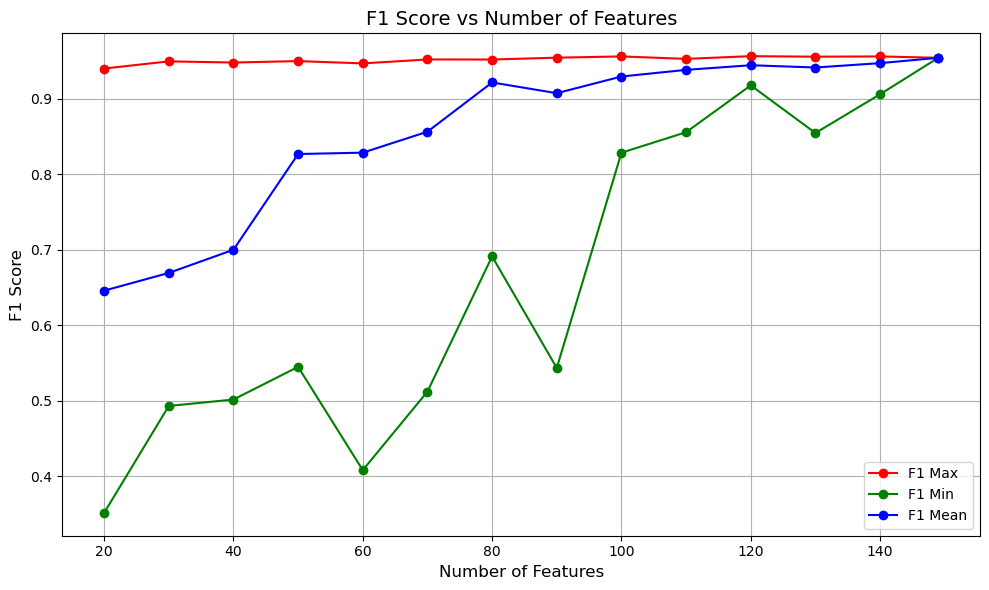

In [11]:
# 分别绘制准确率、精确率、召回率和F1的折线图
import pandas as pd
import matplotlib.pyplot as plt

# 读取ablation_results_varying_features.csv文件
df = pd.read_csv('global_ablation_results.csv')

# 提取横坐标（特征数量）
feature_numbers = df['n_features']

# 提取纵坐标（f1最大值、最小值、平均值）
f1_max = df['f1_max']
f1_min = df['f1_min']
f1_mean = df['f1_mean']

# 创建一个折线图
plt.figure(figsize=(10, 6))

# 绘制f1的最大值、最小值和平均值的折线
plt.plot(feature_numbers, f1_max, label='F1 Max', marker='o', linestyle='-', color='r')
plt.plot(feature_numbers, f1_min, label='F1 Min', marker='o', linestyle='-', color='g')
plt.plot(feature_numbers, f1_mean, label='F1 Mean', marker='o', linestyle='-', color='b')

# 设置图表标题和标签
plt.title('F1 Score vs Number of Features', fontsize=14)
plt.xlabel('Number of Features', fontsize=12)
plt.ylabel('F1 Score', fontsize=12)

# 添加图例
plt.legend()

# 显示图表
plt.grid(True)
plt.tight_layout()
plt.show()


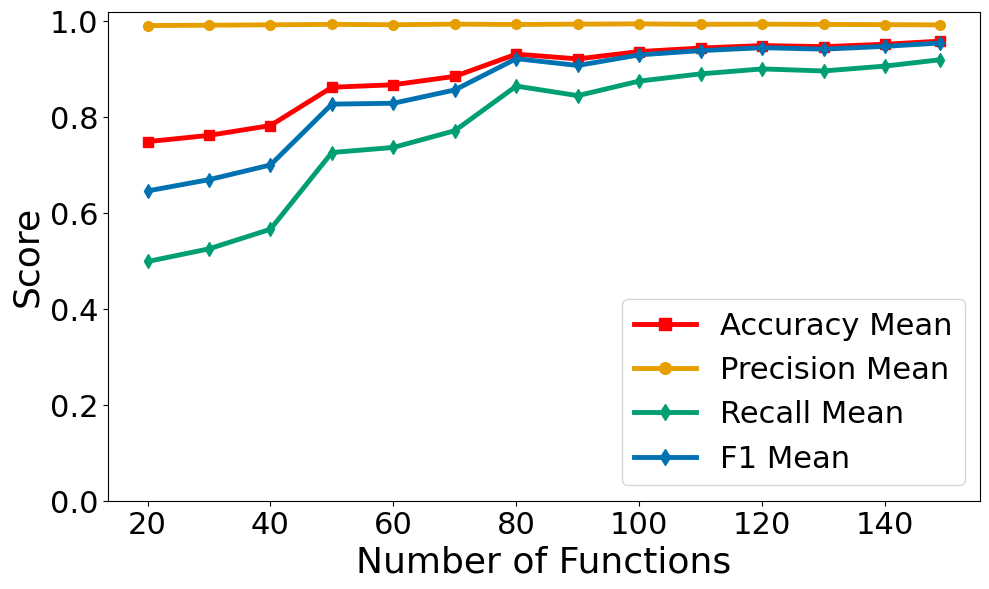

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('global_ablation_results.csv')

feature_numbers = df['n_features']


accuracy_mean = df['accuracy_mean']
precision_mean = df['precision_mean']
recall_mean = df['recall_mean']
f1_mean = df['f1_mean']

plt.figure(figsize=(10, 6))

# 你想要“线和点都变大”，关键是 linewidth + markersize
plt.plot(feature_numbers, accuracy_mean, label='Accuracy Mean',
         marker='s', linestyle='-', linewidth=3.5, markersize=7, color="red")

plt.plot(feature_numbers, precision_mean, label='Precision Mean',
         marker='o', linestyle='-', linewidth=3.5, markersize=7, color="#E69F00")

plt.plot(feature_numbers, recall_mean, label='Recall Mean',
         marker='d', linestyle='-', linewidth=3.5, markersize=7, color="#009E73")

plt.plot(feature_numbers, f1_mean, label='F1 Mean',
         marker='d', linestyle='-', linewidth=3.5, markersize=7, color="#0072B2")


c_blue   = "#0072B2"  # blue
c_orange = "#E69F00"  # orange
c_green  = "#009E73"  # bluish green



plt.xlabel('Number of Functions', fontsize=26)
plt.ylabel('Score', fontsize=26)

# x/y轴刻度数字变大
plt.xticks(fontsize=22)
plt.yticks(fontsize=22)
plt.ylim(bottom=0.0)
# 图例文字变大；markerscale 让图例里的点也更大
plt.legend(fontsize=22, markerscale=1.2, loc='lower right')

plt.tight_layout()
plt.show()


In [ ]:
# 消融实验
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# ========== Generalization Experiments / 消融实验 ==========
def run_ablation_suite_Generalization(
    n_trials_full: int = 80,
    n_trials_ablation: int = 50,
    beta: float = 4.0,
    fpr_low: float = 1e-4,
    fpr_high: float = 2e-2,
    fpr_penalty: float = 0.03,
    fixed_fpr: float = 1e-3,
    seed: int = 42,
    save_csv: str | None = "ablation_results.csv",
    malicious_train_path: str = "preprocess/dataset_0831/normalization/binary/157/merged_filtered_data_train.csv",
    malicious_test_path: str = "preprocess/dataset_0831/normalization/binary/157/merged_filtered_data_test.csv",
):
    benign_df = load_csv(benign_path)
    mal_train_df = load_csv(malicious_train_path)
    mal_test_df = load_csv(malicious_test_path)

    Xb, yb, feat_cols_b = extract_xy(benign_df)
    Xm_tr, ym_tr, _ = extract_xy(mal_train_df)
    Xm_te, ym_te, _ = extract_xy(mal_test_df)

    feat_cols = [c for c in feat_cols_b if c in Xm_tr.columns and c in Xm_te.columns]
    if len(feat_cols) == 0:
        raise ValueError("No common feature columns among datasets.")

    Xb = Xb[feat_cols]
    Xm_tr = Xm_tr[feat_cols]
    Xm_te = Xm_te[feat_cols]

    Xm_train_mal = Xm_tr[ym_tr == 1] if np.any(ym_tr == 1) else Xm_tr
    Xm_test_mal = Xm_te[ym_te == 1] if np.any(ym_te == 1) else Xm_te

    Xb_fit, Xb_tmp = train_test_split(Xb, test_size=0.30, random_state=seed, shuffle=True)
    Xb_cal, Xb_test = train_test_split(Xb_tmp, test_size=0.50, random_state=seed, shuffle=True)

    if len(Xm_train_mal) >= 20:
        Xm_fit, Xm_val = train_test_split(Xm_train_mal, test_size=0.30, random_state=seed, shuffle=True)
    else:
        Xm_fit, Xm_val = Xm_train_mal, Xm_train_mal

    print("==== Data Summary ====")
    print(f"n_features: {len(feat_cols)}")
    print(f"benign_fit={len(Xb_fit)}, benign_calib={len(Xb_cal)}, benign_test={len(Xb_test)}")
    print(f"mal_fit={len(Xm_fit)}, mal_val={len(Xm_val)}, mal_test={len(Xm_test_mal)}")
    print(f"FPR search range=[{fpr_low}, {fpr_high}] when optimize_fpr=True; fixed_fpr={fixed_fpr}\n")

    variants = [
        ("FULL", ModuleSwitches(True, True, True, True), n_trials_full),
        ("No_power", ModuleSwitches(True, True, True, False), n_trials_ablation),
        ("No_t0", ModuleSwitches(True, True, False, True), n_trials_ablation),
        ("No_TwoSided", ModuleSwitches(True, False, True, True), n_trials_ablation),
    ]

    results = []
    for name, sw, ntr in variants:
        print(f"=== Running Variant: {name} (trials={ntr}) ===")
        res = run_variant(
            name=name,
            Xb_fit=Xb_fit, Xb_cal=Xb_cal, Xb_test=Xb_test,
            Xm_fit=Xm_fit, Xm_val=Xm_val, Xm_test=Xm_test_mal,
            feat_cols=feat_cols,
            switches=sw,
            n_trials=ntr,
            beta=beta,
            fpr_low=fpr_low,
            fpr_high=fpr_high,
            fpr_penalty=fpr_penalty,
            seed=seed,
        )

        # ====== 计算“真正 accuracy” ======
        # test accuracy
        if all(k in res for k in ["test_TN", "test_FP", "test_FN", "test_TP"]):
            tpr = res["test_TP"] / (res["test_TP"] + res["test_FN"]) if (res["test_TP"] + res["test_FN"]) > 0 else 0
            tnr = res["test_TN"] / (res["test_TN"] + res["test_FP"]) if (res["test_TN"] + res["test_FP"]) > 0 else 0
            res["test_accuracy"] = (tpr + tnr) / 2

        # calib accuracy（如果你 run_variant 也返回 calib 混淆矩阵，就一并算）
        if all(k in res for k in ["calib_TN", "calib_FP", "calib_FN", "calib_TP"]):
            calib_tpr = res["calib_TP"] / (res["calib_TP"] + res["calib_FN"]) if (res["calib_TP"] + res["calib_FN"]) > 0 else 0
            calib_tnr = res["calib_TN"] / (res["calib_TN"] + res["calib_FP"]) if (res["calib_TN"] + res["calib_FP"]) > 0 else 0
            res["calib_accuracy"] = (calib_tpr + calib_tnr) / 2

        results.append(res)

        # ====== 打印 ======
        print(f"  fpr_target={res['fpr_target']:.6g}, thr={res['threshold']:.6f}")
        print(f"  CALIB: P={res['calib_precision']:.4f} R={res['calib_recall']:.4f} "
              f"F1={res['calib_f1']:.4f} FPR={res['calib_fpr']:.6f} AUC={res['calib_auc']:.4f}")
        if "calib_accuracy" in res:
            print(f"         ACC={res['calib_accuracy']:.4f}")
        print(f"  TEST : P={res['test_precision']:.4f} R={res['test_recall']:.4f} "
              f"F1={res['test_f1']:.4f} FPR={res['test_fpr']:.6f} AUC={res['test_auc']:.4f}")
        if "test_accuracy" in res:
            print(f"         ACC={res['test_accuracy']:.4f}")
        print(f"  CM   : TN={res['test_TN']} FP={res['test_FP']} FN={res['test_FN']} TP={res['test_TP']}\n")

    df = pd.DataFrame(results)

    # 仍然用你原来的排序逻辑（按 test_f{beta} 优先）；也可以改成按 accuracy 排序
    fbeta_col = f"test_f{beta}"
    sort_cols = [fbeta_col, "test_f1", "test_recall"]
    df = df.sort_values(by=sort_cols, ascending=False)

    print("==== Ablation Summary (sorted) ====")
    cols_show = [
        "variant", "fpr_target", "threshold",
        "test_accuracy", "test_precision", "test_recall", "test_f1", "test_fpr", "test_auc",
        "test_TN", "test_FP", "test_FN", "test_TP",
    ]
    # 兼容：如果某些列不存在（比如 test_accuracy），就过滤掉
    cols_show = [c for c in cols_show if c in df.columns]
    print(df[cols_show].to_string(index=False))

    if save_csv:
        # CSV 浮点数统一 4 位小数
        df.to_csv(save_csv, index=False, float_format="%.4f")
        print(f"\nSaved to: {save_csv}")

    return df


# ====== 你的 benign 路径 ======
#benign_path = f"./contrast_dataset_bind9.16.2/good/normalized_dataset_good.csv"
benign_path = f"./contrast_dataset_bind9.18.6/good/normalized_dataset_good.csv"


if __name__ == "__main__":
    x_values = ["lockcram", "camp", "nxns", "sigjam", "keysig"]

    all_variant_results = []  # 存每个x跑出来的“所有variants”结果（整表）

    for x in x_values:
        print(f"\nRunning ablation suite for {x}...")


        # detector 超参
        # t0 = trial.suggest_float("t0", 0.0, 6.5) if switches.use_gate_t0 else 0.0
        # gamma = trial.suggest_float("gamma", 0.5, 4.0) if switches.use_power_transform else 1.0
        # trim_frac = trial.suggest_float("trim_frac", 0.00001, 0.001)#消融实验改动
        # benign_path = f"./contrast_dataset_bind9.18.6/good/normalized_dataset_good.csv"
        # malicious_train_path=f"./contrast_dataset_bind9.18.6/{x}/train_normalized.csv",
        # malicious_test_path=f"./contrast_dataset_bind9.18.6/{x}/test_normalized.csv",

        df_x = run_ablation_suite_Generalization(
            n_trials_full=80,
            n_trials_ablation=20,
            beta=1,
            fpr_low=1e-6,
            fpr_high=1e-4,
            fpr_penalty=0.03,
            fixed_fpr=1e-3,
            seed=42,
            save_csv=None,  # 单次不存
            malicious_train_path=f"./contrast_dataset_bind9.18.6/{x}/train_normalized.csv",
            malicious_test_path=f"./contrast_dataset_bind9.18.6/{x}/test_normalized.csv",
        )

        df_x = df_x.copy()
        df_x["x"] = x

        # 明细表建议保留这些列（你也可以加上 test_f1, test_auc 等）
        keep_cols = [
            "x", "variant",
            "test_accuracy", "test_precision", "test_recall",
            "test_f1", "test_auc",
            "test_TN", "test_FP", "test_FN", "test_TP",
            "threshold", "fpr_target",
        ]
        keep_cols = [c for c in keep_cols if c in df_x.columns]
        all_variant_results.append(df_x[keep_cols])

    # ========== 拼成总明细：每行 = (x, variant) ==========
    all_df = pd.concat(all_variant_results, ignore_index=True)

    # 明细保存（可选，但一般很有用）
    all_df.to_csv("ablation_results_all_x_all_variants.csv", index=False, float_format="%.4f")
    print(all_df.to_string(index=False))
    # ========== 统计每个 variant 在不同 x 下的平均 Accuracy/Precision/Recall ==========
    metrics = ["test_accuracy", "test_precision", "test_recall", "test_f1"]
    metrics = [m for m in metrics if m in all_df.columns]

    summary_mean = (
        all_df.groupby("variant")[metrics]
              .mean()
              .reset_index()
              .rename(columns={
                  "test_accuracy": "avg_accuracy",
                  "test_precision": "avg_precision",
                  "test_recall": "avg_recall",
                  "test_f1": "avg_f1",
              })
    )

    summary_std = (
        all_df.groupby("variant")[metrics]
              .std()
              .reset_index()
              .rename(columns={
                  "test_accuracy": "std_accuracy",
                  "test_precision": "std_precision",
                  "test_recall": "std_recall",
              })
    )

    summary = summary_mean.merge(summary_std, on="variant", how="left")

    # 排序：优先平均 accuracy，然后 precision/recall
    sort_cols = [c for c in ["avg_accuracy", "avg_precision", "avg_recall"] if c in summary.columns]
    summary = summary.sort_values(by=sort_cols, ascending=False)

    # 输出到 CSV（仅 4 位小数）
    summary.to_csv("ablation_results_by_variant_avg.csv", index=False, float_format="%.4f")

    print("\nSaved:")
    print(" - ablation_results_all_x_all_variants.csv (每个x的每个variant明细，4位小数)")
    print(" - ablation_results_by_variant_avg.csv     (每个variant跨x均值/标准差，4位小数)")
    print("\nSummary:")
    print(summary.to_string(index=False))



Running ablation suite for lockcram...
==== Data Summary ====
n_features: 149
benign_fit=7000, benign_calib=1500, benign_test=1500
mal_fit=1484, mal_val=637, mal_test=700
FPR search range=[1e-06, 0.0001] when optimize_fpr=True; fixed_fpr=0.001

=== Running Variant: FULL (trials=80) ===
best_t0: 6.48166803013987
best_gamma: 3.655511635674635
best_trim_frac: 0.0007138740640637799
  fpr_target=1.02729e-06, thr=14.626186
  CALIB: P=1.0000 R=0.9178 F1=0.9571 FPR=0.000000 AUC=0.9904
  TEST : P=0.9916 R=0.8457 F1=0.9129 FPR=0.003333 AUC=0.9954
         ACC=0.9212
  CM   : TN=1495 FP=5 FN=108 TP=592

=== Running Variant: No_power (trials=20) ===
best_t0: 6.450609462149432
best_gamma: 1.0
best_trim_frac: 0.0007779611875758465
  fpr_target=1.03172e-06, thr=11.671032
  CALIB: P=1.0000 R=0.8497 F1=0.9188 FPR=0.000000 AUC=0.9903
  TEST : P=0.9947 R=0.8014 F1=0.8877 FPR=0.002000 AUC=0.9963
         ACC=0.8997
  CM   : TN=1497 FP=3 FN=139 TP=561

=== Running Variant: No_t0 (trials=20) ===
best_t0: 0